# Telecom Customer Churn: Who Leaves, and Why

Roughly 1 customer in 4 churned at this telecom (26.54 % of 7,043 customers). The goal isn’t to confirm that number: it’s to identify which customers are most at risk, what drives their departure, and what a retention team could realistically do about it.

**Approach:**
1. Data loading and cleaning
2. SQL exploration: which segments churn the most?
3. Python EDA built around a few testable hypotheses
4. Feature engineering
5. Modeling: a baseline, then a stronger model
6. Interpretation with SHAP
7. Takeaways and retention recommendations

In [1]:
import sys
sys.path.append('..')

import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import shap
import re
import statsmodels.formula.api as smf

from pathlib import Path
from IPython.display import display, Markdown
from scipy.stats import chi2_contingency, mannwhitneyu
from matplotlib.colors import LinearSegmentedColormap

from src.data_loading import load_raw_data, clean_data
from src.features import build_features
from src.model import split_data, train_baseline, train_advanced, evaluate

COLORS = {'No': '#3B6A9C', 'Yes': '#E76F51'}   # retained = steel blue, churned = coral

sns.set_theme(style='white', context='notebook', font_scale=1.05)
plt.rcParams.update({
    'figure.dpi': 110,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.titleweight': 'bold',
    'axes.titlesize': 13,
    'axes.titlepad': 14,
})

sns.set_style('whitegrid')
%matplotlib inline

## 1. Data loading and cleaning

In [2]:
df_raw = load_raw_data('../data/raw/telco_churn.csv')
df = clean_data(df_raw)
df.head()

,customerid,gender,seniorcitizen,partner,dependents,tenure,phoneservice,multiplelines,internetservice,onlinesecurity,...,deviceprotection,techsupport,streamingtv,streamingmovies,contract,paperlessbilling,paymentmethod,monthlycharges,totalcharges,churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.info()
df.describe(include='all')

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerid        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   seniorcitizen     7043 non-null   int64  
 3   partner           7043 non-null   str    
 4   dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   phoneservice      7043 non-null   str    
 7   multiplelines     7043 non-null   str    
 8   internetservice   7043 non-null   str    
 9   onlinesecurity    7043 non-null   str    
 10  onlinebackup      7043 non-null   str    
 11  deviceprotection  7043 non-null   str    
 12  techsupport       7043 non-null   str    
 13  streamingtv       7043 non-null   str    
 14  streamingmovies   7043 non-null   str    
 15  contract          7043 non-null   str    
 16  paperlessbilling  7043 non-null   str    
 17  paymen

,customerid,gender,seniorcitizen,partner,dependents,tenure,phoneservice,multiplelines,internetservice,onlinesecurity,...,deviceprotection,techsupport,streamingtv,streamingmovies,contract,paperlessbilling,paymentmethod,monthlycharges,totalcharges,churn
count,7043,7043,7043.000000,7043,7043,7043.000000,7043,7043,7043,7043,...,7043,7043,7043,7043,7043,7043,7043,7043.000000,7043.000000,7043
unique,7043,2,NaN,2,2,NaN,2,3,3,3,...,3,3,3,3,3,2,4,NaN,NaN,2
top,7590-VHVEG,Male,NaN,No,No,NaN,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,NaN,NaN,No
freq,1,3555,NaN,3641,4933,NaN,6361,3390,3096,3498,...,3095,3473,2810,2785,3875,4171,2365,NaN,NaN,5174
mean,NaN,NaN,0.162147,NaN,NaN,32.371149,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,64.761692,2279.734304,NaN
std,NaN,NaN,0.368612,NaN,NaN,24.559481,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.090047,2266.794470,NaN
min,NaN,NaN,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.250000,0.000000,NaN
25%,NaN,NaN,0.000000,NaN,NaN,9.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,35.500000,398.550000,NaN
50%,NaN,NaN,0.000000,NaN,NaN,29.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,70.350000,1394.550000,NaN
75%,NaN,NaN,0.000000,NaN,NaN,55.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,89.850000,3786.600000,NaN


## 2. SQL exploration

I load the cleaned data into an in-memory SQLite table and run the queries from `sql/exploration_queries.sql`. It's the fastest way to know whether there's a story worth digging into with pandas and matplotlib, and since there's no server to set up, anyone can rerun the notebook as is.

In [4]:
conn = sqlite3.connect(':memory:')
df.to_sql('customers', conn, index=False, if_exists='replace')

sql_script = Path('../sql/exploration_queries.sql').read_text(encoding='utf-8')

# Each query is preceded by a numbered comment ("-- 1. ...").
# Split on those headers so every block runs as its own query.
# [1:] drops the file header that comes before query 1.
blocks = re.split(r'(?m)^-- (?=\d+\.\s)', sql_script)[1:]

query_results = {}
for block in blocks:
    title, _, query = block.partition('\n')
    title = title.strip()
    result = pd.read_sql_query(query.strip(), conn)
    query_results[title] = result
    display(Markdown(f'**{title}**'))
    display(result)

conn.close()

**1. Overall churn rate**

,total_customers,churners,churn_rate_pct
0,7043,1869,26.54


**2. Churn rate by contract type**

,contract,num_customers,churn_rate_pct
0,Month-to-month,3875,42.71
1,One year,1473,11.27
2,Two year,1695,2.83


**3. Churn rate by tenure bucket**

...

,onlinesecurity,techsupport,num_customers,churn_rate_pct
0,No,No,2553,48.96
1,No,Yes,945,22.33
2,Yes,No,920,21.30
3,Yes,Yes,1099,9.01
4,No internet service,No internet service,1526,7.40


**6. Average monthly charges: churned vs. retained**

,churn,avg_monthly_charges,num_customers
0,No,61.27,5174
1,Yes,74.44,1869


**7. Priority risk segment: month-to-month + under 12 months + electronic check**

,segment_size,pct_of_customers,churners,churn_rate_pct,pct_of_all_churners
0,917,13.02,586,63.9,31.35


**What stands out :**

Churn is far from evenly spread. Month-to-month customers leave at 42.7%, against 2.8% on two-year contracts, and nearly half of customers in their first year are gone (48.3%). Electronic check users churn at 45.3%, almost three times the rate of customers on automatic payment. Having neither online security nor tech support puts churn at 49%, while having both brings it down to 9%.

Stacking month-to-month, under 12 months of tenure and electronic check isolates 917 customers, about 13% of the base, with a 63.9% churn rate. That small group accounts for roughly a third of everyone who left.

These are raw cross-tabs, so some effects surely overlap (new customers are mostly on month-to-month, for one). Untangling that is the job of the next section.

## 3. Exploratory analysis

The SQL pass points to four hypotheses worth testing. Each one gets a chart and a chi-square test (or a comparison of means where relevant).

- **H1**: month-to-month customers churn more than customers on one- or two-year contracts.
- **H2**: churn drops as tenure grows, and new customers are the most at risk.
- **H3**: customers paying by electronic check churn more than those on automatic payment.
- **H4**: customers without online security or tech support churn more than those with both.

These factors overlap (new customers are mostly on month-to-month contracts, for example), so I also check whether the contract effect holds at equal tenure.

In [5]:
from scipy.stats import mannwhitneyu

from src.visualization import (BOX, COLORS, apply_style, chi2_report, churn_rate,
                           finish_axes, plot_churn_bar, save_figure, set_title)

apply_style()
overall = churn_rate(df['churn'])

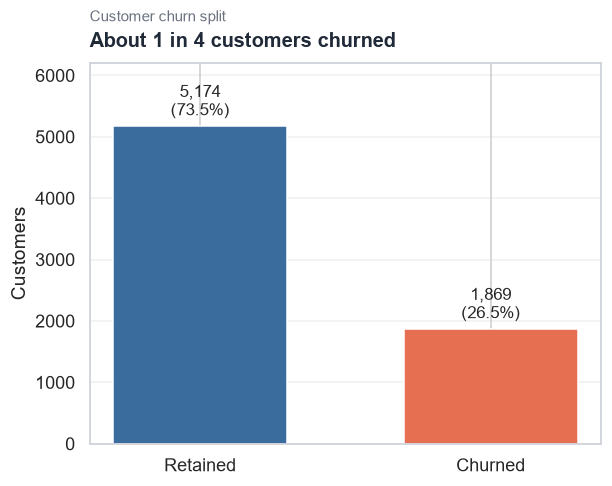

In [6]:
counts = df['churn'].value_counts().reindex(['No', 'Yes'])
pct = counts / counts.sum() * 100

fig, ax = plt.subplots(figsize=(6, 4.5))
bars = ax.bar(['Retained', 'Churned'], counts.values,
              color=[COLORS['No'], COLORS['Yes']], width=0.6)
ax.bar_label(bars, labels=[f'{n:,}\n({p:.1f}%)' for n, p in zip(counts, pct)],
             padding=4, fontsize=11)
ax.set_ylim(0, counts.max() * 1.2)
ax.set_ylabel('Customers')
ax.yaxis.grid(True, alpha=0.3)
ax.set_axisbelow(True)
set_title(ax, 'About 1 in 4 customers churned', 'Customer churn split')

save_figure('churn_distribution.png')
plt.show()

The classes are imbalanced (73.5% / 26.5%). That's not extreme, but it means accuracy alone would be misleading: a model that predicts "no churn" for everyone would already score 73%. I'll rely on stratified splits and on recall and PR-AUC when I get to modeling.

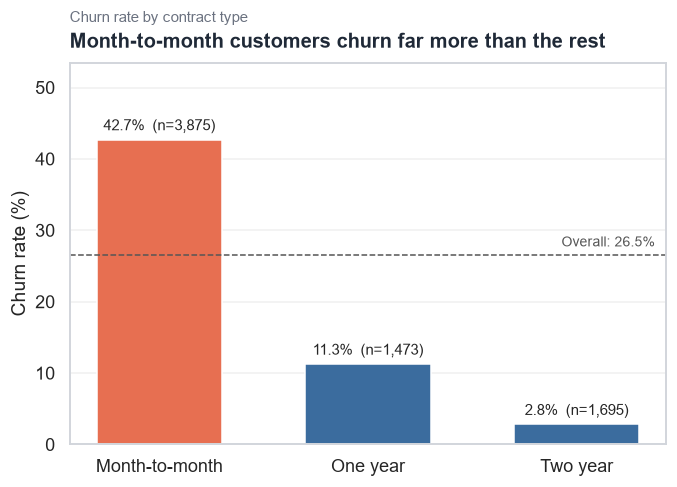

chi2 = 1184.6 (dof = 2), p = 5.86e-258, Cramér's V = 0.41


In [7]:
# H1: churn by contract type
plot_churn_bar(df, 'contract',
               headline='Month-to-month customers churn far more than the rest',
               subject='Churn rate by contract type',
               fname='churn_by_contract.png',
               order=['Month-to-month', 'One year', 'Two year'])
chi2_report(df, 'contract')

H1 holds, and more strongly than I expected. Month-to-month customers churn at 42.7%, against 11.3% on one-year and 2.8% on two-year contracts, and they make up close to 9 in 10 of all churners. The chi-square test rules out chance (p < 0.001) and Cramér's V (0.41) points to a strong association.

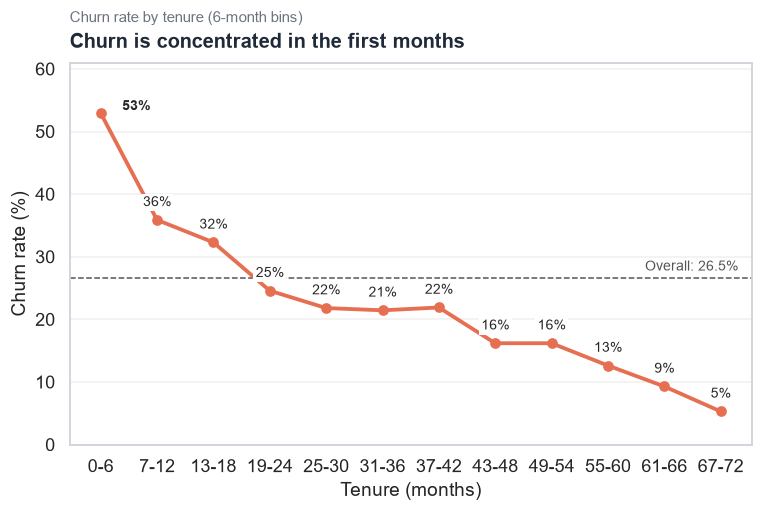

Median tenure: churned = 10 months, retained = 38 months (Mann-Whitney p = 2.42e-208)


In [8]:
# H2: churn rate by tenure (6-month bins)
edges = list(range(0, 73, 6))
labels = ['0-6'] + [f'{a + 1}-{a + 6}' for a in range(6, 72, 6)]
tenure_bin = pd.cut(df['tenure'], bins=edges, labels=labels, include_lowest=True)

rate = df.groupby(tenure_bin, observed=True)['churn'].apply(churn_rate)
x = np.arange(len(rate))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(x, rate.values, marker='o', lw=2.5, color=COLORS['Yes'], zorder=3)

# Labels above each point; the first one goes to the right because the curve drops steeply
for i, y in enumerate(rate.values):
    if i == 0:
        ax.annotate(f'{y:.0f}%', (i, y), textcoords='offset points', xytext=(14, 2),
                    ha='left', fontsize=9, fontweight='bold')
    else:
        ax.annotate(f'{y:.0f}%', (i, y), textcoords='offset points', xytext=(0, 9),
                    ha='center', fontsize=9, bbox=BOX, zorder=4)

ax.set_xticks(x)
ax.set_xticklabels(rate.index.astype(str))
ax.set_ylim(0, rate.max() * 1.15)
ax.set_xlabel('Tenure (months)')
ax.set_ylabel('Churn rate (%)')
finish_axes(ax, overall)
set_title(ax, 'Churn is concentrated in the first months', 'Churn rate by tenure (6-month bins)')

save_figure('churn_by_tenure.png')
plt.show()

# Churned vs. retained: compare tenure distributions (non-parametric, tenure is skewed)
t_churn = df.loc[df['churn'] == 'Yes', 'tenure']
t_stay = df.loc[df['churn'] == 'No', 'tenure']
_, p = mannwhitneyu(t_churn, t_stay)
print(f'Median tenure: churned = {t_churn.median():.0f} months, retained = {t_stay.median():.0f} months '
      f'(Mann-Whitney p = {p:.2e})')

H2 holds. Nearly half of customers in their first year leave (48.3%), against under 10% once they pass four years. The median churner left after 10 months, versus 38 for those who stayed (Mann-Whitney, p < 0.001). Whatever drives people to leave, it mostly happens early. The spike of loyal customers at 72 months is likely the edge of the observation window, not a real cluster.

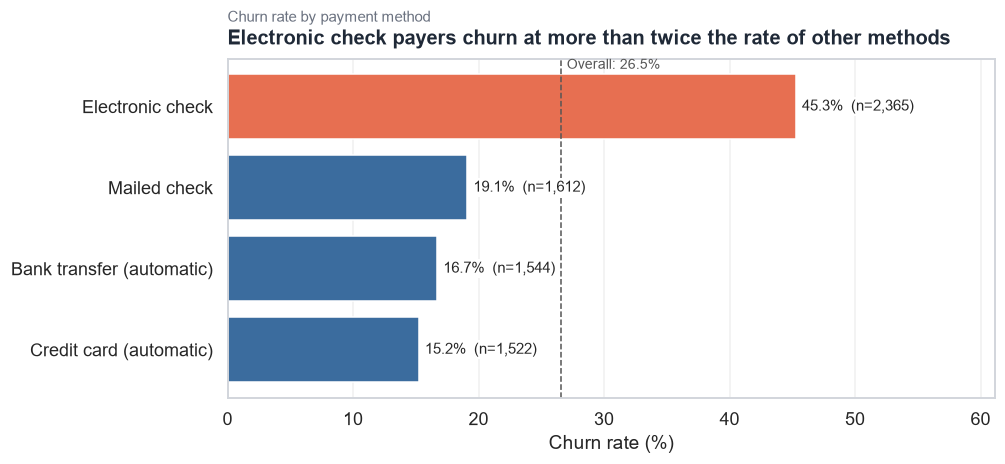

chi2 = 648.1 (dof = 3), p = 3.68e-140, Cramér's V = 0.30


In [9]:
# H3: churn by payment method
plot_churn_bar(df, 'paymentmethod',
               headline='Electronic check payers churn at more than twice the rate of other methods',
               subject='Churn rate by payment method',
               fname='churn_by_payment_method.png',
               horizontal=True, figsize=(9, 4))
chi2_report(df, 'paymentmethod')

H3 holds, and the gap is bigger than I expected: electronic check payers churn at 45.3%, against 15.2% to 19.1% for the other methods, roughly 2.4 to 3 times higher. The payment method itself is probably not the cause. It's more likely a proxy for less engaged customers who never set up autopay, and it overlaps with contract type. Among month-to-month customers only, the gap narrows but stays. Either way, it's a cheap signal to monitor.

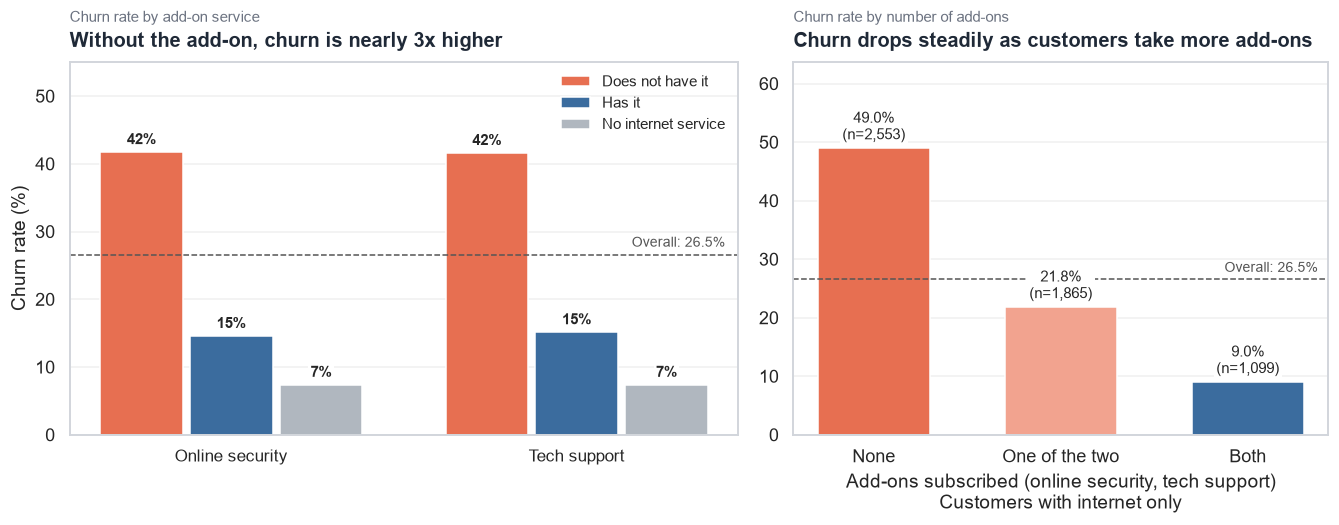

chi2 = 850.0 (dof = 2), p = 2.66e-185, Cramér's V = 0.35
chi2 = 828.2 (dof = 2), p = 1.44e-180, Cramér's V = 0.34


In [10]:
# H4: churn by add-on services (online security, tech support)
GREY = '#B0B7BF'
SALMON = '#F2A38F'

internet = df[df['onlinesecurity'] != 'No internet service'].copy()
internet['n_addons'] = ((internet['onlinesecurity'] == 'Yes').astype(int)
                        + (internet['techsupport'] == 'Yes').astype(int))

fig, axes = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={'width_ratios': [1.25, 1]})

# Left: for each service, churn rate of customers without it / with it / without internet
ax = axes[0]
services = [('onlinesecurity', 'Online security'), ('techsupport', 'Tech support')]
groups = [('No', 'Does not have it', COLORS['Yes']),
          ('Yes', 'Has it', COLORS['No']),
          ('No internet service', 'No internet service', GREY)]
width = 0.26

for j, (value, label, color) in enumerate(groups):
    rates = [churn_rate(df.loc[df[col] == value, 'churn']) for col, _ in services]
    bars = ax.bar(np.arange(2) + (j - 1) * width, rates, width=width * 0.92,
                  color=color, label=label)
    ax.bar_label(bars, labels=[f'{r:.0f}%' for r in rates], padding=3,
                 fontsize=10, fontweight='bold', bbox=BOX)

ax.set_xticks(np.arange(2))
ax.set_xticklabels([name for _, name in services], fontsize=11)
ax.set_ylim(0, 55)
ax.set_ylabel('Churn rate (%)')
set_title(ax, 'Without the add-on, churn is nearly 3x higher', 'Churn rate by add-on service')
ax.legend(frameon=False, loc='upper right', fontsize=9.5)

# Right: churn by number of add-ons (customers with internet only)
ax = axes[1]
g = internet.groupby('n_addons')['churn'].agg(rate=churn_rate, n='size')
bars = ax.bar(['None', 'One of the two', 'Both'], g['rate'],
              color=[COLORS['Yes'], SALMON, COLORS['No']], width=0.6)
ax.bar_label(bars, labels=[f'{r:.1f}%\n(n={n:,})' for r, n in zip(g['rate'], g['n'])],
             padding=3, fontsize=10, bbox=BOX)
ax.set_ylim(0, g['rate'].max() * 1.3)
ax.set_xlabel('Add-ons subscribed (online security, tech support)\nCustomers with internet only')
ax.set_ylabel('')
set_title(ax, 'Churn drops steadily as customers take more add-ons', 'Churn rate by number of add-ons')

for ax in axes:
    finish_axes(ax, overall)

plt.tight_layout()
save_figure('churn_by_addon_services.png')
plt.show()

chi2_report(df, 'onlinesecurity')
chi2_report(df, 'techsupport')

H4 holds too. Customers without online security or tech support churn at roughly 42%, against about 15% for those who have them, and the pattern is almost identical for both services (chi-square p < 0.001 in each case). That similarity suggests it isn't really about the specific service, but about how invested a customer is in the product overall. Among customers with internet, churn falls steadily with the number of add-ons: 49% with none, 21,8% with one, 9% with both.

Customers with no internet service churn the least (about 7%), but that's a different population, not a "yes" to add-ons. They can't subscribe in the first place, so I leave them out of the add-on comparison.

For recommendations, this points toward getting customers to adopt any add-on rather than pushing one specific service. One caveat: add-ons are not randomly assigned, so adopting one may be a sign of engagement rather than the cause of staying.

### **Does the contract effect hold at equal tenure?**

New customers are mostly on month-to-month contracts, so part of the H1 gap could simply be a tenure effect. To check, I compare contracts within the same tenure band, then estimate the contract effect with a logistic regression that controls for tenure.

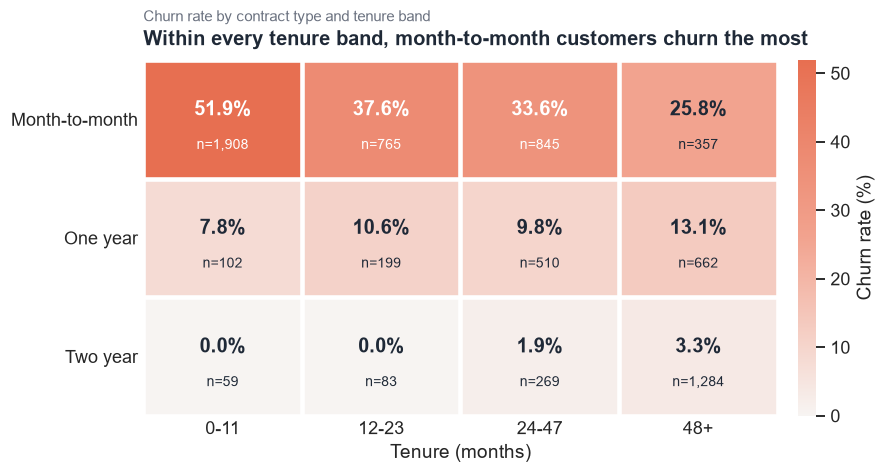

In [11]:
# Contract effect at equal tenure: churn rate per contract within each tenure band
MIN_N = 30   # below this, the rate is too noisy to show

tenure_edges = [-1, 11, 23, 47, np.inf]
tenure_labels = ['0-11', '12-23', '24-47', '48+']
df['tenure_band'] = pd.cut(df['tenure'], bins=tenure_edges, labels=tenure_labels)

contract_order = ['Month-to-month', 'One year', 'Two year']
churn_flag = (df['churn'] == 'Yes')

rates = (churn_flag.groupby([df['contract'], df['tenure_band']], observed=False)
                   .mean().mul(100).unstack().loc[contract_order])
counts = (df.groupby(['contract', 'tenure_band'], observed=False)
            .size().unstack().loc[contract_order])

# White -> coral colormap, built from the palette
cmap = LinearSegmentedColormap.from_list('churn', ['#F7F4F2', '#F2A38F', COLORS['Yes']])

fig, ax = plt.subplots(figsize=(8, 4.2))
vmax = rates.where(counts >= MIN_N).max().max()
im = ax.imshow(rates.where(counts >= MIN_N).values, cmap=cmap, vmin=0, vmax=vmax, aspect='auto')

for i in range(rates.shape[0]):
    for j in range(rates.shape[1]):
        n = counts.iloc[i, j]
        if n < MIN_N:
            ax.text(j, i, f'n={n}\n(too few)', ha='center', va='center', fontsize=9, color='#9CA3AF')
            continue
        r = rates.iloc[i, j]
        txt_color = 'white' if r > 0.6 * vmax else '#1F2937'
        ax.text(j, i - 0.08, f'{r:.1f}%', ha='center', va='center',
                fontsize=13, fontweight='bold', color=txt_color)
        ax.text(j, i + 0.22, f'n={n:,}', ha='center', va='center', fontsize=9, color=txt_color)

# White gaps between cells
ax.set_xticks(np.arange(-0.5, rates.shape[1]), minor=True)
ax.set_yticks(np.arange(-0.5, rates.shape[0]), minor=True)
ax.grid(which='minor', color='white', linewidth=3)
ax.grid(which='major', visible=False)
ax.tick_params(which='both', length=0)

ax.set_xticks(range(len(tenure_labels)))
ax.set_xticklabels(tenure_labels)
ax.set_yticks(range(len(contract_order)))
ax.set_yticklabels(contract_order)
ax.set_xlabel('Tenure (months)')
ax.set_ylabel('')
for spine in ax.spines.values():
    spine.set_visible(False)

cbar = fig.colorbar(im, ax=ax, fraction=0.04, pad=0.03)
cbar.set_label('Churn rate (%)')
cbar.outline.set_visible(False)

set_title(ax, 'Within every tenure band, month-to-month customers churn the most',
          'Churn rate by contract type and tenure band')

save_figure('churn_contract_by_tenure.png')
plt.show()

In [12]:
df['churn_bin'] = (df['churn'] == 'Yes').astype(int)
ref = 'C(contract, Treatment("Month-to-month"))'

# Model A: contract only. Model B: contract + tenure band
m_naive = smf.logit(f'churn_bin ~ {ref}', data=df).fit(disp=0)
m_adj = smf.logit(f'churn_bin ~ {ref} + C(tenure_band)', data=df).fit(disp=0)


def odds_table(model, label):
    """Odds ratios, 95% CI and p-values for the contract terms of a fitted logit."""
    out = pd.DataFrame({
        'OR': np.exp(model.params),
        'CI low': np.exp(model.conf_int()[0]),
        'CI high': np.exp(model.conf_int()[1]),
        'p': model.pvalues,
    })
    out = out[out.index.str.contains('contract')]
    out.index = [i.split('T.')[-1].rstrip(']') for i in out.index]
    return out.round(3).add_suffix(f' ({label})')


res = pd.concat([odds_table(m_naive, 'raw'), odds_table(m_adj, 'adjusted')], axis=1)
display(res[['OR (raw)', 'OR (adjusted)', 'CI low (adjusted)', 'CI high (adjusted)', 'p (adjusted)']])

,OR (raw),OR (adjusted),CI low (adjusted),CI high (adjusted),p (adjusted)
One year,0.170,0.235,0.194,0.284,0.0
Two year,0.039,0.056,0.041,0.077,0.0


The contract effect holds at equal tenure. In every tenure band, month-to-month customers churn the most: 51.9% in the first year against 7.8% on one-year and 0% on two-year contracts, and still 25.8% after four years against 13.1% and 3.3%. The gap narrows as tenure grows but never closes, so H1 is not just a tenure effect in disguise.

A logistic regression tells the same story. On its own, a one-year contract carries about 6 times lower odds of churning than month-to-month (OR = 0.17), and a two-year contract about 26 times lower (OR = 0.039). After controlling for tenure band, those become about 4 times lower (OR = 0.235, 95% CI 0.19 to 0.28) and about 18 times lower (OR = 0.056, 95% CI 0.04 to 0.08), with p < 0.001 in both cases. Tenure explains part of the raw gap, but not all of it.

Two caveats. The 0% for two-year contracts in the first two bands rests on small groups (59 and 83 customers), and it is probably partly built in, since leaving early on a long contract typically means paying a penalty. And this is still an association: customers who choose a long contract may already be more loyal, so I wouldn't promise the same drop from pushing people onto annual plans. It does earn contract type its place as a feature in the model.

## 4. Feature engineering

The EDA pointed to contract type, tenure, payment method and add-on services as the main drivers. This step turns the cleaned data into a numeric table a model can use: categorical columns are encoded, [a few features are derived from the EDA findings], and the identifier column is dropped. The logic lives in `build_features` (see `src/features.py`).

Then the data is split into train (80%) and test (20%). The split is stratified, so both sets keep the same churn rate (26.54%), and the test set is left untouched until the final evaluation.

In [13]:
df_features = build_features(df)

X = df_features.drop(columns=['churn'])
y = df_features['churn']

assert 'churn_bin' not in X.columns and 'customerid' not in X.columns

X_train, X_test, y_train, y_test = split_data(X, y)
print(f'Train: {X_train.shape} | Test: {X_test.shape}')
print(f'Churn rate — train: {y_train.mean():.2%} | test: {y_test.mean():.2%}')

Train: (5634, 27) | Test: (1409, 27)
Churn rate — train: 26.54% | test: 26.54%


## 5. Modeling

Two models, deliberately: logistic regression as an interpretable baseline, then a Random Forest to see whether a more flexible model finds something the baseline misses. Both use `class_weight="balanced"` since churn is the minority class, so accuracy alone would be misleading here.

In [14]:
# Training set
baseline = train_baseline(X_train, y_train)
advanced = train_advanced(X_train, y_train)

In [15]:
from sklearn.model_selection import cross_val_score, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for name, model in [('Logistic regression', baseline), ('Random Forest', advanced)]:
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring='roc_auc')
    print(f'{name}: AUC {scores.mean():.3f} ± {scores.std():.3f}')

Logistic regression: AUC 0.846 ± 0.012
Random Forest: AUC 0.847 ± 0.011


In [16]:
# Baseline: logistic regression
print('--- Baseline (Logistic Regression) ---')
evaluate(baseline, X_test, y_test)

--- Baseline (Logistic Regression) ---
              precision    recall  f1-score   support

    Retained       0.90      0.72      0.80      1035
       Churn       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409

AUC-ROC: 0.842
Confusion matrix:
[[749 286]
 [ 83 291]]


In [17]:
# Advanced: Random Forest
print('--- Random Forest ---')
evaluate(advanced, X_test, y_test)

--- Random Forest ---
              precision    recall  f1-score   support

    Retained       0.90      0.74      0.82      1035
       Churn       0.52      0.78      0.63       374

    accuracy                           0.75      1409
   macro avg       0.71      0.76      0.72      1409
weighted avg       0.80      0.75      0.77      1409

AUC-ROC: 0.844
Confusion matrix:
[[771 264]
 [ 83 291]]


Cross-validation on the training set puts the two models level: AUC of 0.846 ± 0.012 for the logistic regression and 0.847 ± 0.011 for the Random Forest. The gap is far smaller than the spread between folds. On the test set they also catch the same number of churners (291 out of 374, about 78%). The one difference is false alarms: the Random Forest flags 264 loyal customers by mistake instead of 286, which lifts precision on churners from 0.50 to 0.52.

In practice, the extra complexity buys very little on this data. I keep the Random Forest for the SHAP step because it handles interactions between features, and I use the logistic regression as a sanity check on the direction of the effects.

## 6. Interpretation (SHAP)

A model that says "this customer will churn" isn't very useful to a retention team on its own — they need to know *why*, so they know what to offer.

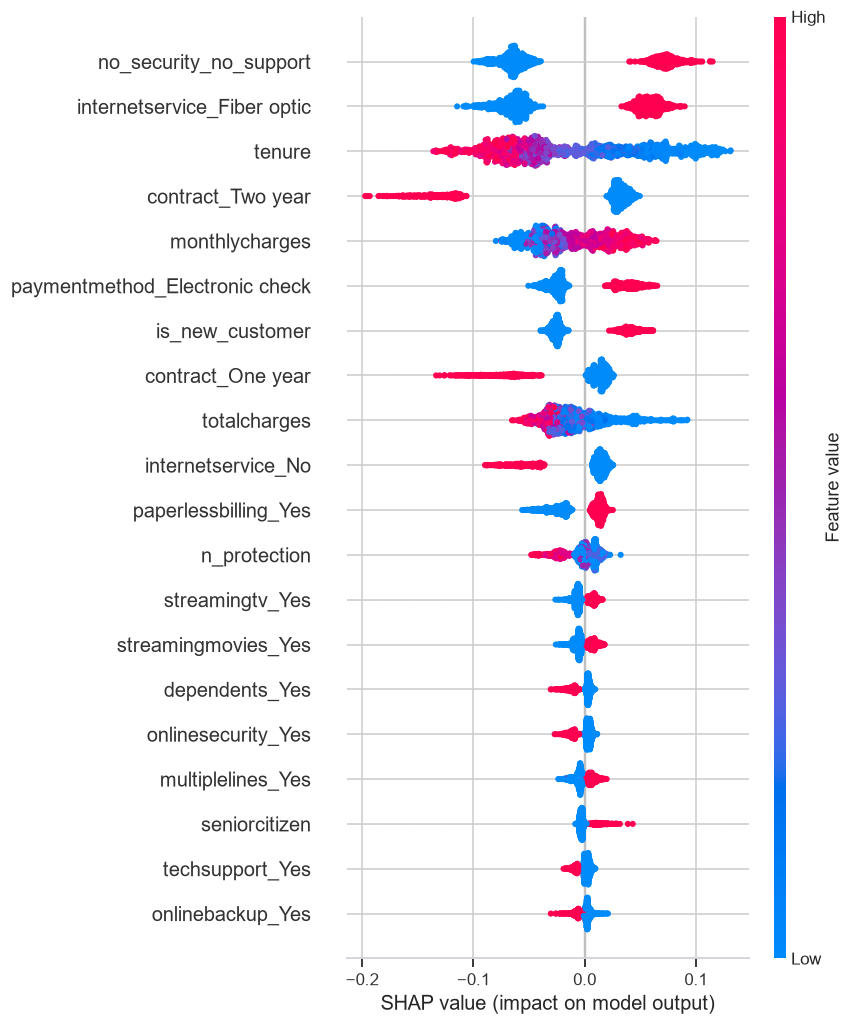

In [18]:
explainer = shap.TreeExplainer(advanced)
shap_values = explainer.shap_values(X_test)

# Handle both shap API versions: list-per-class, or a 3D (n, features, classes) array
if isinstance(shap_values, list):
    shap_values_churn = shap_values[1]
elif shap_values.ndim == 3:
    shap_values_churn = shap_values[:, :, 1]
else:
    shap_values_churn = shap_values

shap.summary_plot(shap_values_churn, X_test, show=False)
plt.savefig('../reports/figures/shap_summary.png', dpi=150, bbox_inches='tight')
plt.show()

The strongest signals pushing predicted churn up are the lack of both security and tech support, fiber optic internet, electronic check payment and being a new customer. A two-year contract, a one-year contract and a long tenure pull it down the most. Each of the four EDA hypotheses shows up in the model: contract type (H1), tenure and new customers (H2), electronic check payment (H3), and missing security and support (H4), which comes out as the single strongest signal. Tenure, total charges and the new-customer flag overlap, so their weight is shared between them.

One result wasn't in the hypotheses: fiber optic ranks second. These customers also pay more each month, so the model may be picking up price as much as the service itself. SHAP shows what the model relies on, not what causes churn, so this is a lead to investigate rather than a conclusion.

In [19]:
# Verification of the SHAP result on fiber optic (not part of the modeling pipeline).
# Question: does fiber churn more only because it costs more, or because of missing support?

internet = df.query("internetservice != 'No'").copy()


def churn_table(data, by):
    """Churn rate (%) and number of customers, DSL vs fiber, for each group in `by`."""
    out = (data.groupby([by, 'internetservice'], observed=True)['churn_bin']
               .agg(rate='mean', n='size'))
    out['rate'] = (out['rate'] * 100).round(1)
    return out.unstack()


# 1) Same monthly price band: does fiber still churn more?
internet['price_band'] = pd.qcut(df['monthlycharges'], 4)  # quartiles over all customers
print('Churn by monthly price band')
display(churn_table(internet, 'price_band'))

# 2) Same support setup: does fiber still churn more?
internet['no_sec_sup'] = (internet['onlinesecurity'] == 'No') & (internet['techsupport'] == 'No')
print('Churn by security / tech support setup')
display(churn_table(internet, 'no_sec_sup'))

# 3) Size of the highest-risk segment: fiber, no security, no tech support
seg = ((df['internetservice'] == 'Fiber optic')
       & (df['onlinesecurity'] == 'No')
       & (df['techsupport'] == 'No'))
print(f"Segment: {seg.sum():,} customers ({seg.mean():.1%} of the base)")
print(f"Churn rate: {df.loc[seg, 'churn_bin'].mean():.1%} vs {df['churn_bin'].mean():.1%} overall")
print(f"Share of all churners: {df.loc[seg, 'churn_bin'].sum() / df['churn_bin'].sum():.1%}")

Churn by monthly price band


rate                   n            
internetservice   DSL Fiber optic     DSL Fiber optic
price_band                                           
(18.249, 35.5]   36.0         NaN   236.0         NaN
(35.5, 70.35]    21.1        59.0  1605.0       161.0
(70.35, 89.85]    6.4        50.9   530.0      1227.0
(89.85, 118.75]   2.0        33.8    50.0      1708.0

Churn by security / tech support setup


rate                 n            
internetservice   DSL Fiber optic   DSL Fiber optic
no_sec_sup                                         
False            11.0        24.5  1633        1331
True             35.4        55.0   788        1765

Segment: 1,765 customers (25.1% of the base)
Churn rate: 55.0% vs 26.5% overall
Share of all churners: 52.0%


The check says it isn't only price. In the same price band, fiber customers churn far more than DSL ones (51% against 6% between 70 and 90 a month, with more than 500 customers in each group), and the gap holds whatever the support setup: 24.5% against 11.0% for customers with security or tech support, 55.0% against 35.4% for those with neither. A price band isn't a like-for-like comparison, and the data can't say why fiber stands out (service quality, competition and the kind of customer who picks fiber are all possible).

The highest-risk group is fiber customers with no security and no tech support: 1,765 customers, a quarter of the base, churning at 55% and accounting for 52% of all churners.

In [20]:
# Check used in the takeaways: do the two high-risk segments overlap,
# and how many churners does a team reach by calling the top 20% of scored customers?
seg_a = (df['contract'] == 'Month-to-month') & (df['tenure'] < 12)
seg_b = ((df['internetservice'] == 'Fiber optic')
         & (df['onlinesecurity'] == 'No') & (df['techsupport'] == 'No'))
churners = df['churn_bin'] == 1

for name, mask in [('Month-to-month, under 12 months', seg_a),
                   ('Fiber, no security, no support', seg_b),
                   ('Either of the two', seg_a | seg_b)]:
    print(f"{name}: {mask.sum():,} customers ({mask.mean():.1%} of the base), "
          f"churn {df.loc[mask, 'churn_bin'].mean():.1%}, "
          f"{(mask & churners).sum() / churners.sum():.1%} of all churners")

proba = advanced.predict_proba(X_test)[:, 1]
top = proba >= np.quantile(proba, 0.80)
print(f"Top 20% by risk score: {y_test[top].sum() / y_test.sum():.1%} of the churners in the test set")

Month-to-month, under 12 months: 1,908 customers (27.1% of the base), churn 51.9%, 53.0% of all churners
Fiber, no security, no support: 1,765 customers (25.1% of the base), churn 55.0%, 52.0% of all churners
Either of the two: 2,936 customers (41.7% of the base), churn 48.4%, 76.0% of all churners
Top 20% by risk score: 50.5% of the churners in the test set


In [21]:
df.loc[~(seg_a | seg_b), 'churn_bin'].mean()

np.float64(0.1093255417579742)

## 7. Takeaways and recommendations

**Overall churn rate: 26.5%** (1,869 of 7,043 customers)

**What the data shows:**

1. **Contract type is the clearest pattern in the raw numbers.** Month-to-month customers churn at 42.7%, against 11.3% on one-year contracts and just 2.8% on two-year contracts. Both contract columns sit in the SHAP top eight, so the model agrees.
2. **Risk is front-loaded.** Churned customers had an average tenure of 18 months, versus 37.6 months for retained customers. A lot of the damage happens early in the relationship.
3. **Missing support is the strongest signal in the model.** Among customers with internet, those with neither online security nor tech support churn at 55.0% on fiber and 35.4% on DSL, against 24.5% and 11.0% for those with at least one of the two. The flag built from H4 ranks first in the SHAP plot.
4. **Fiber optic stands out, and not only because of price.** Within the same price band, and within the same support setup, fiber customers churn more than DSL ones (51% against 6% between 70 and 90 a month, for example). The data can't say why: service quality, competition and the kind of customer who picks fiber are all possible.
5. **Payment method is a useful, if indirect, signal.** Electronic check payers churn at 45.3%, versus 15-19% for automatic payment methods. It's probably not the payment method itself causing churn, but it's a cheap, easy-to-monitor proxy.

**Two overlapping segments to prioritize:**

- **Month-to-month, under 12 months of tenure:** 1,908 customers (27.1% of the base), 51.9% churn.
- **Fiber, no security, no tech support:** 1,765 customers (25.1% of the base), 55.0% churn.

The two overlap on 737 customers. Together they cover 2,936 customers (41.7% of the base) with a 48.4% churn rate, and 76.0% of all churners. Everyone else churns at 10.9%.

**Model performance (Random Forest):**

- AUC-ROC: 0.844, about the same as the logistic regression baseline (0.842), so the simpler model does almost as well
- Recall on the churn class: about 78% (291 of 374 churners caught in the test set)
- Precision on the churn class: 52%, so about one flagged customer in two is a false alarm. That trade-off only makes sense if a retention call costs less than a lost customer, which I haven't tested.

**What I'd recommend doing with this:**

1. Focus the retention budget on these two segments rather than spreading it across the whole base. They hold three churners out of four in 42% of the customers.
2. Test an incentive to move new month-to-month customers onto a longer contract. Customers who choose longer contracts may be different to begin with, so compare an offered group with a control group before rolling it out.
3. Pilot a free trial of tech support and online security for fiber customers who don't have them, again with a control group. Both are associated with lower churn, but that doesn't prove adding them keeps customers.
4. Look into fiber service quality (outages, speed complaints, competitor offers), since nothing in this dataset explains the gap.
5. Use electronic check payment as a lightweight risk flag to prioritize check-ins, and only push customers to switch to automatic payment if a test shows it helps.
6. Score the customer base monthly and hand the retention team a ranked outreach list, instead of relying on reactive, complaint-driven contact. In the test set, calling only the top 20% by risk score would reach 50.5% of the churners, about 2.5 times what calling at random would.